In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)



In [ ]:
df=pd.read_csv("/content/student_exam_performance.csv")
df.head()

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,...,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
0,STU_000001,20,Female,High School,Public,Middle,NaN,Rural,78.36,2.95,...,Medium,27,95,86,NaN,9.39,90.40,A,Pass,High
1,STU_000002,17,Male,High School,Public,Middle,NaN,Suburban,73.40,2.89,...,Easy,4,100,86,87.17,6.31,86.21,A,Pass,High
2,STU_000003,18,Other,Undergraduate,Public,Middle,Master,Urban,82.76,3.35,...,Easy,28,96,74,63.77,9.87,76.11,B,Pass,Medium
3,STU_000004,20,Male,High School,Public,Middle,High School,Suburban,60.61,2.57,...,Medium,16,97,77,59.51,9.68,79.74,B,Pass,Medium
4,STU_000005,16,Female,High School,Private,High,Bachelor,Suburban,74.79,2.84,...,Medium,28,98,52,84.64,10.00,50.66,D,Pass,Low


In [ ]:
print("Shape:", df.shape)

df.info()

Shape: (100000, 44)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 44 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   student_id                  100000 non-null  object 
 1   age                         100000 non-null  int64  
 2   gender                      100000 non-null  object 
 3   education_level             100000 non-null  object 
 4   school_type                 100000 non-null  object 
 5   family_income               100000 non-null  object 
 6   parent_education            93474 non-null   object 
 7   urban_rural                 100000 non-null  object 
 8   previous_exam_score         100000 non-null  float64
 9   previous_gpa                92207 non-null   float64
 10  attendance_percentage       90137 non-null   float64
 11  assignment_completion_rate  100000 non-null  float64
 12  class_participation         100000 non-null  object 


In [ ]:
df.describe()

,age,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,practice_tests_completed,...,physical_activity_hours,stress_level,internet_access,online_course_hours,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score
count,100000.000000,100000.000000,92207.000000,90137.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,...,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,90387.000000,100000.000000,100000.000000
mean,17.005740,69.531033,2.780892,84.616882,69.724405,2.995725,2.094970,0.299800,2.004763,5.509170,...,2.487579,9.375640,0.918760,2.999453,15.501440,92.492150,57.298240,78.398551,8.927373,61.950072
std,1.999562,11.379108,0.478218,7.922485,12.127179,1.719466,1.266066,0.458173,2.005719,2.501131,...,2.413386,1.081613,0.273205,2.983732,8.644356,4.609376,15.028787,14.105155,1.354875,15.863644
min,14.000000,30.000000,1.000000,46.340000,20.000000,0.500000,0.250000,0.000000,0.000000,0.000000,...,0.000000,5.000000,0.000000,0.000000,1.000000,85.000000,0.000000,17.030000,1.000000,0.000000
25%,15.000000,61.820000,2.460000,79.210000,61.480000,1.720000,1.170000,0.000000,0.580000,4.000000,...,0.720000,9.000000,1.000000,0.860000,8.000000,88.000000,47.000000,68.790000,8.220000,51.240000
50%,17.000000,69.530000,2.780000,84.750000,69.570000,2.670000,1.840000,0.000000,1.380000,5.000000,...,1.730000,10.000000,1.000000,2.080000,16.000000,92.000000,57.000000,79.000000,9.490000,61.960000
75%,19.000000,77.232500,3.110000,90.170000,77.920000,3.910000,2.730000,1.000000,2.770000,7.000000,...,3.480000,10.000000,1.000000,4.150000,23.000000,96.000000,67.000000,89.210000,10.000000,72.730000
max,20.000000,100.000000,4.000000,100.000000,100.000000,12.000000,10.000000,1.000000,15.000000,20.000000,...,12.000000,10.000000,1.000000,20.000000,30.000000,100.000000,100.000000,100.000000,10.000000,100.000000


In [ ]:
df["pass_status"].value_counts()


,count
pass_status,
Pass,77389
Fail,22611


In [ ]:
df["pass_status"].value_counts(normalize=True) * 100

,proportion
pass_status,
Pass,77.389
Fail,22.611


In [ ]:
df["performance_grade"].value_counts()

,count
performance_grade,
D,34886
F,22611
C,21794
B,13190
A,7519


In [ ]:
df["performance_level"].value_counts()

,count
performance_level,
Low,45123
Medium,41999
High,12878


In [ ]:
df.isnull().sum()[df.isnull().sum() > 0].sort_values(ascending=False)

,0
attendance_percentage,9863
time_management_score,9613
notes_quality,8407
previous_gpa,7793
sleep_quality,6994
parent_education,6526
device_availability,2965


In [ ]:
numeric_features = df.select_dtypes(include=["int64", "float64"]).columns

df.groupby("pass_status")[numeric_features].mean().T

pass_status,Fail,Pass
age,17.003671,17.006345
previous_exam_score,61.974054,71.738980
previous_gpa,2.480577,2.868783
attendance_percentage,82.833591,85.138114
assignment_completion_rate,66.547264,70.652681
study_hours_per_day,2.283495,3.203819
self_study_hours,1.602486,2.238860
private_tuition,0.296449,0.300779
online_learning_hours,2.002807,2.005335
practice_tests_completed,4.566583,5.784569


In [ ]:
categorical_cols = df.select_dtypes(include="object").columns

categorical_cols

Index(['student_id', 'gender', 'education_level', 'school_type',
       'family_income', 'parent_education', 'urban_rural',
       'class_participation', 'study_consistency', 'study_environment',
       'study_method', 'revision_frequency', 'notes_quality', 'sleep_quality',
       'break_frequency', 'motivation_level', 'device_availability',
       'educational_app_usage', 'exam_difficulty', 'performance_grade',
       'pass_status', 'performance_level'],
      dtype='object')

In [ ]:
pd.crosstab(
    df["gender"],
    df["pass_status"],
    normalize="index"
) * 100

pass_status,Fail,Pass
gender,,
Female,22.620339,77.379661
Male,22.560554,77.439446
Other,23.607689,76.392311


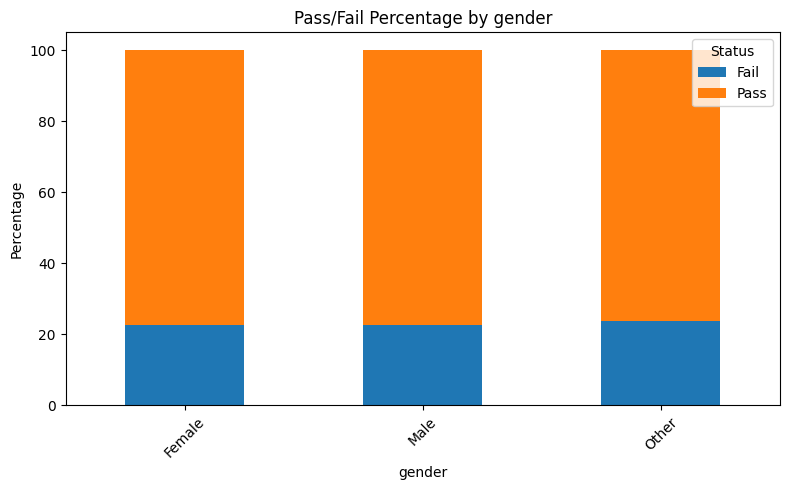

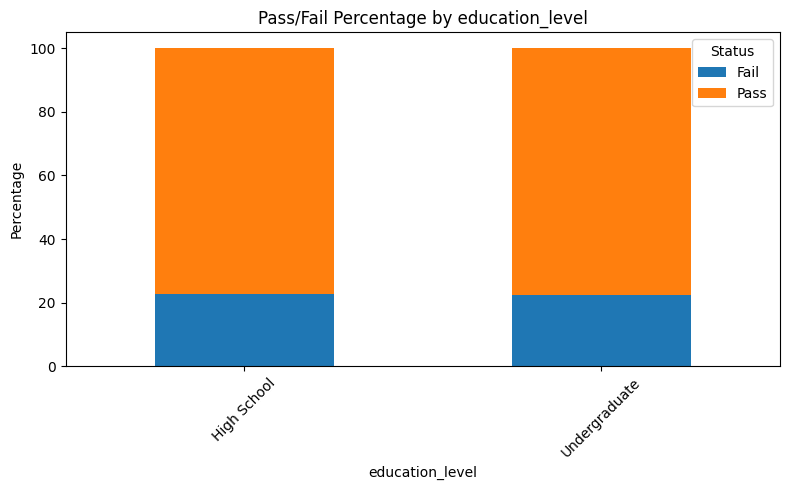

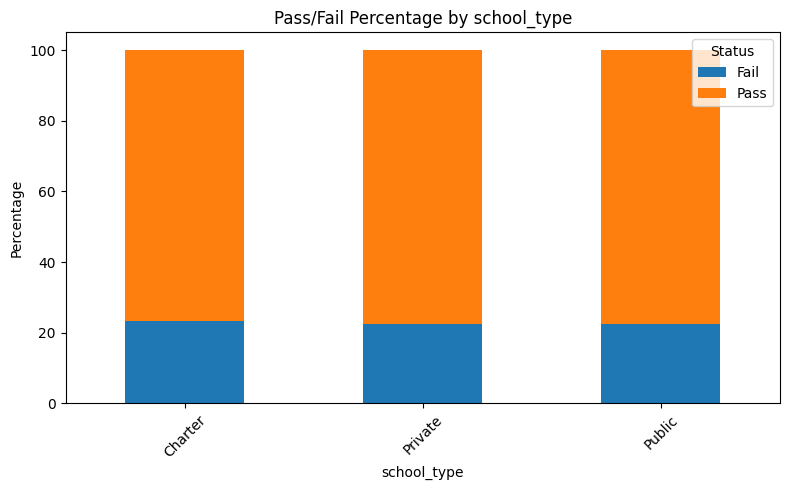

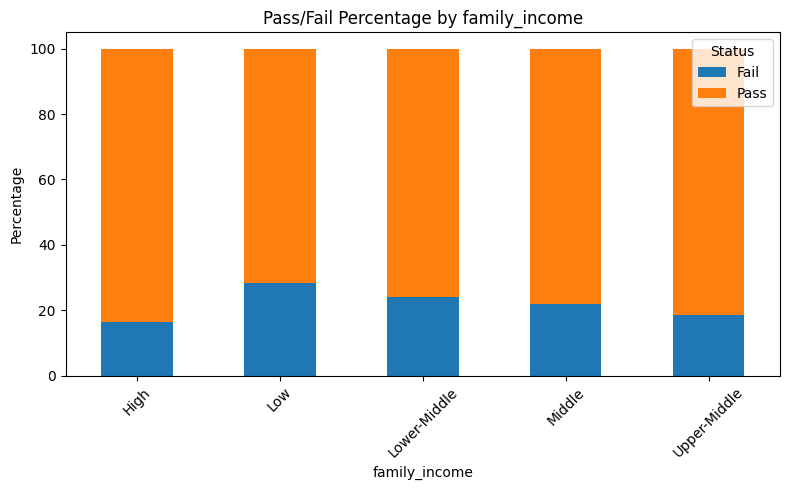

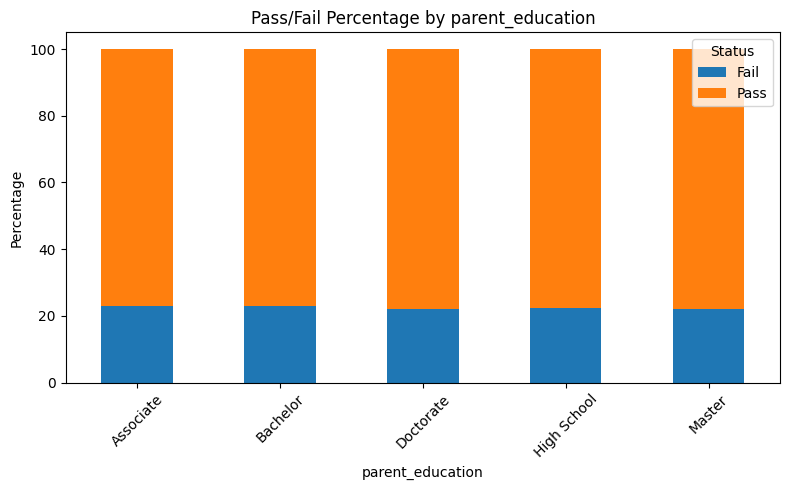

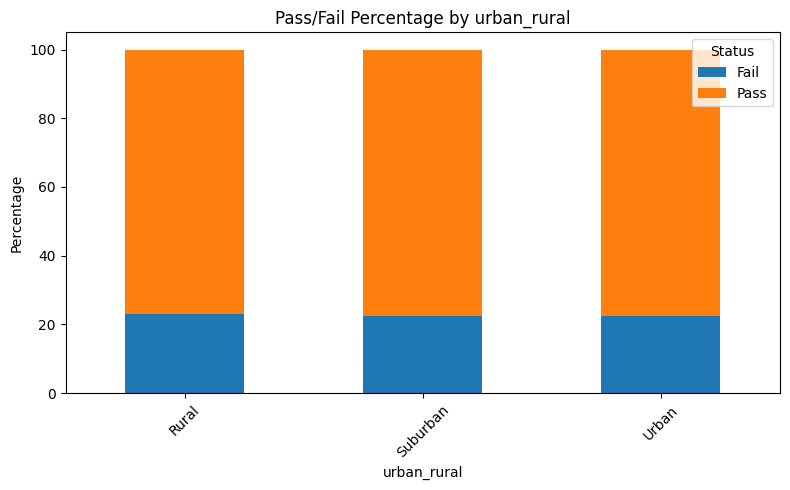

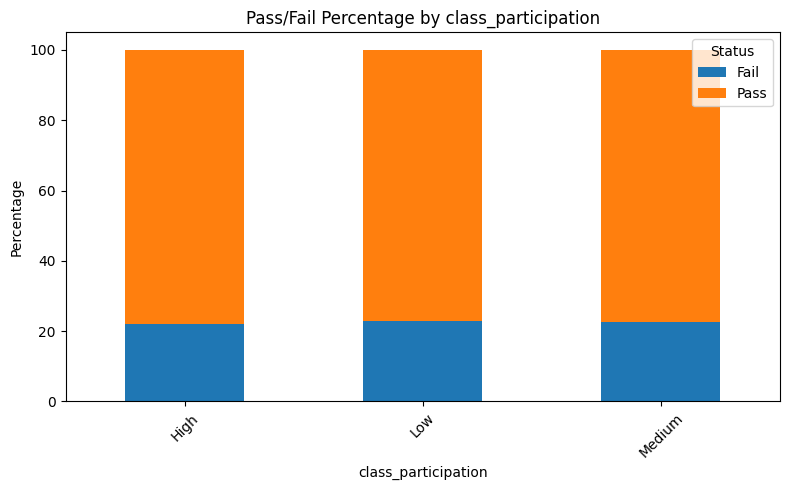

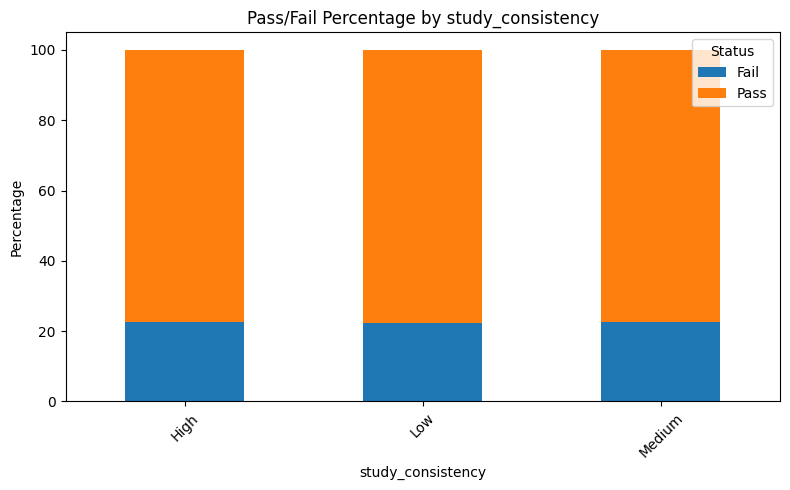

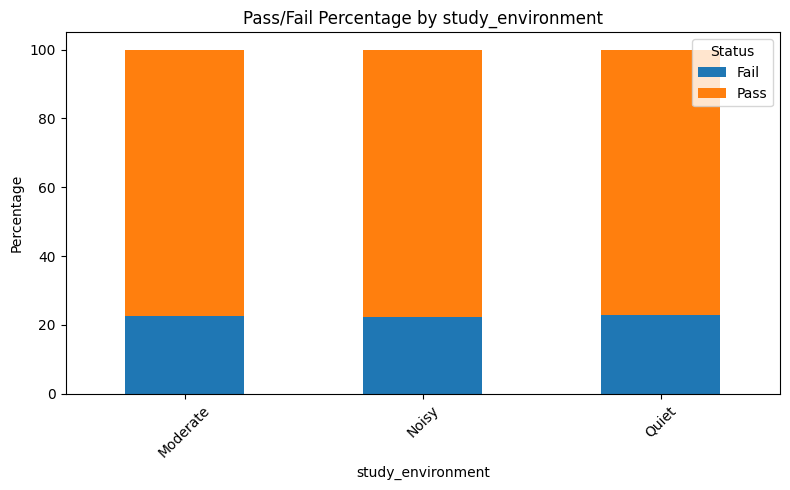

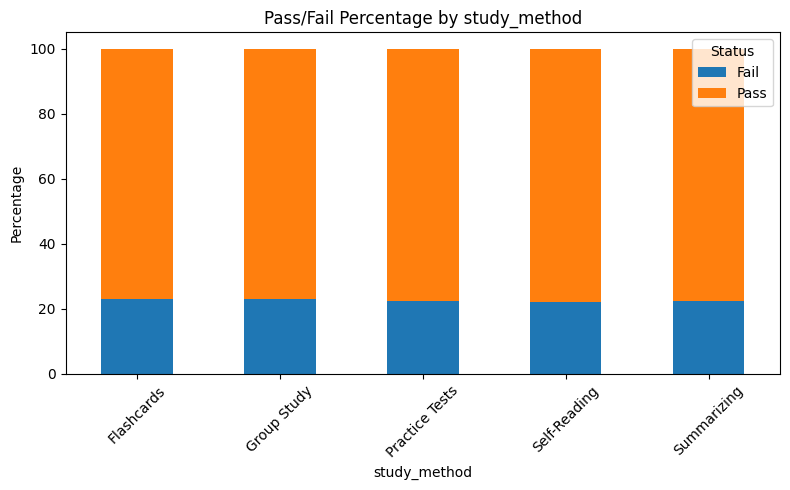

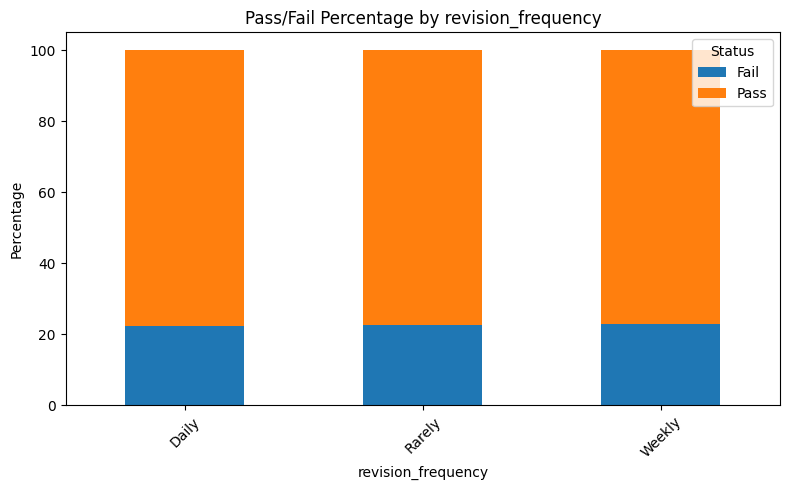

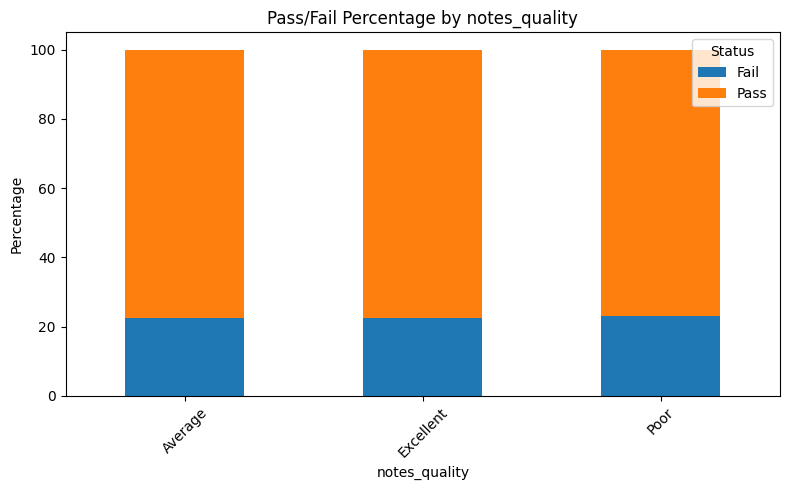

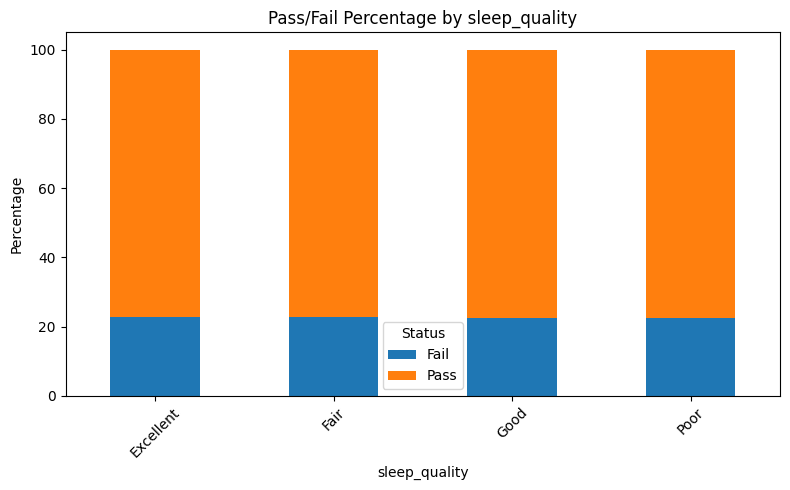

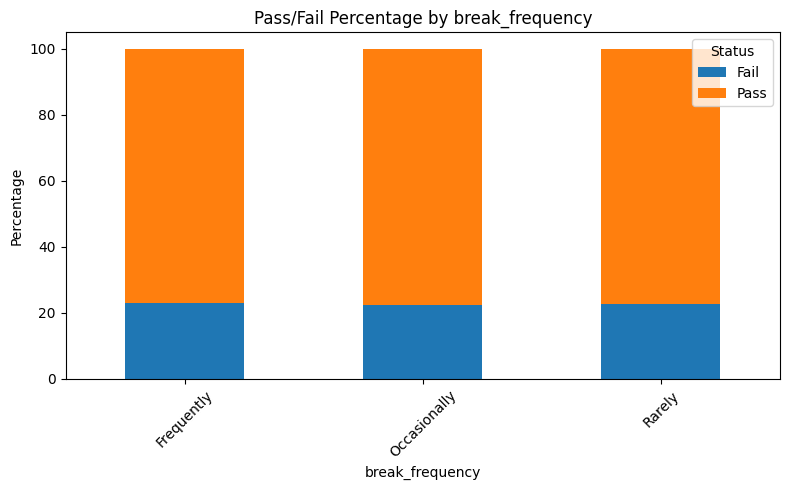

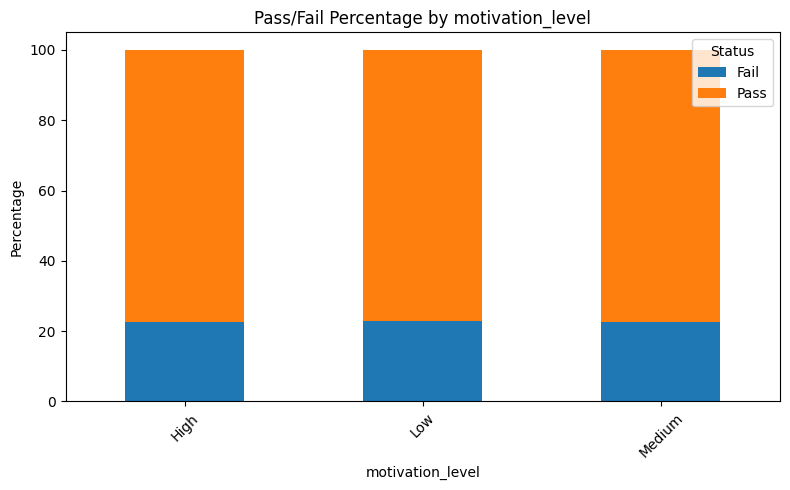

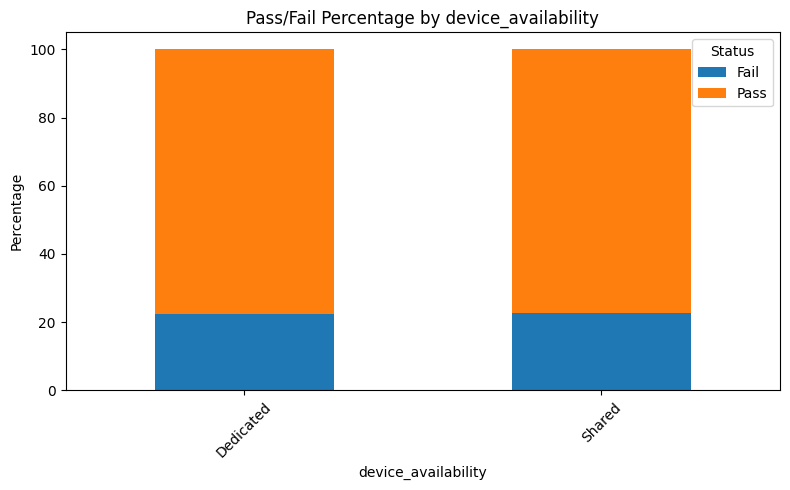

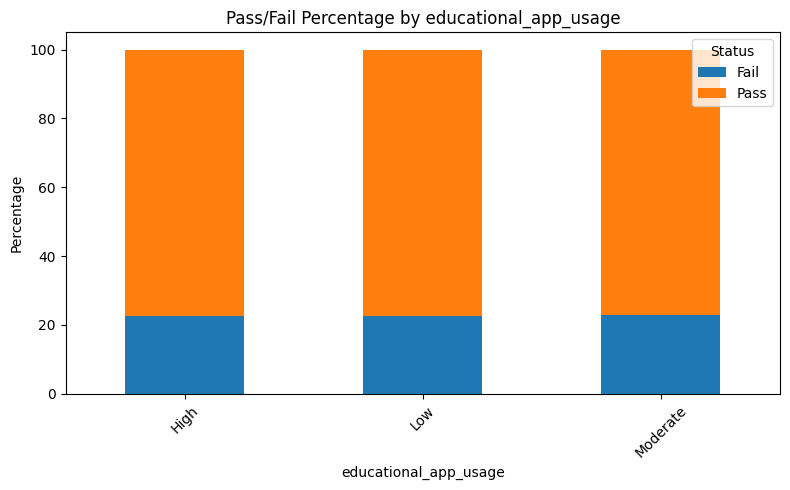

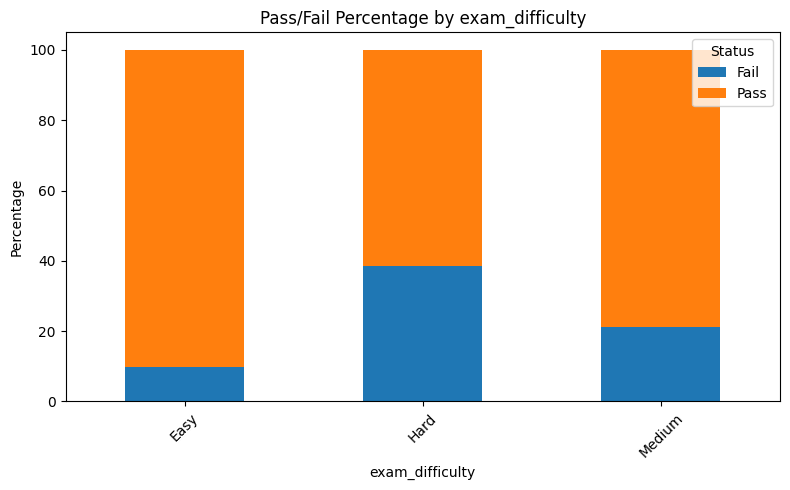

In [ ]:
categorical_features = [
    col for col in df.select_dtypes(include="object").columns
    if col not in [
        "student_id",
        "pass_status",
        "performance_grade",
        "performance_level"
    ]
]

for feature in categorical_features:

    pd.crosstab(
        df[feature],
        df["pass_status"],
        normalize="index"
    ).mul(100).plot(
        kind="bar",
        stacked=True,
        figsize=(8, 5)
    )

    plt.title(f"Pass/Fail Percentage by {feature}")
    plt.xlabel(feature)
    plt.ylabel("Percentage")
    plt.xticks(rotation=45)
    plt.legend(title="Status")
    plt.tight_layout()
    plt.show()

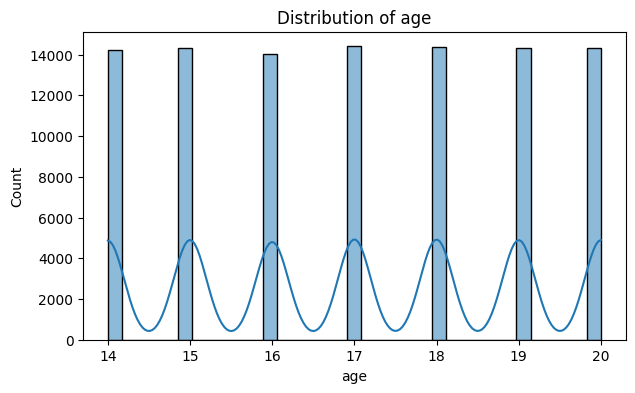

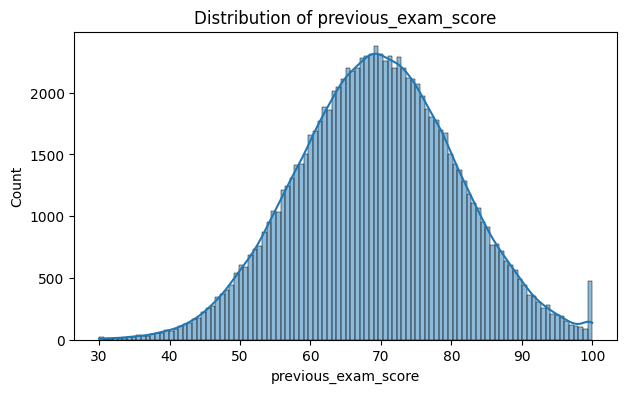

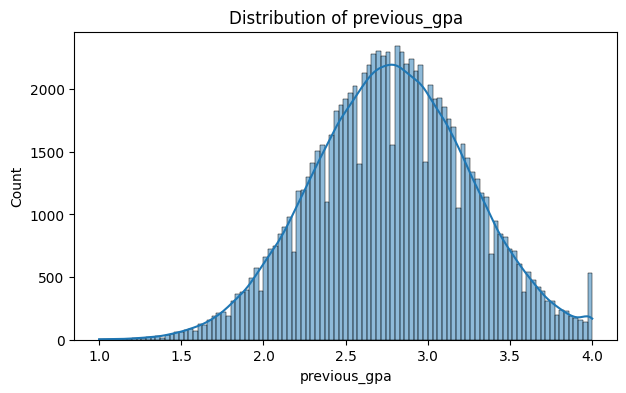

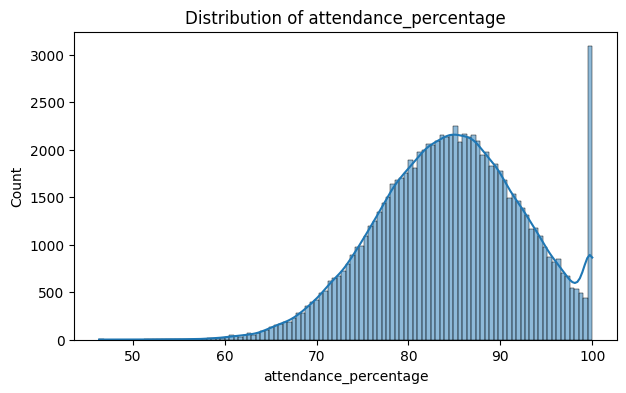

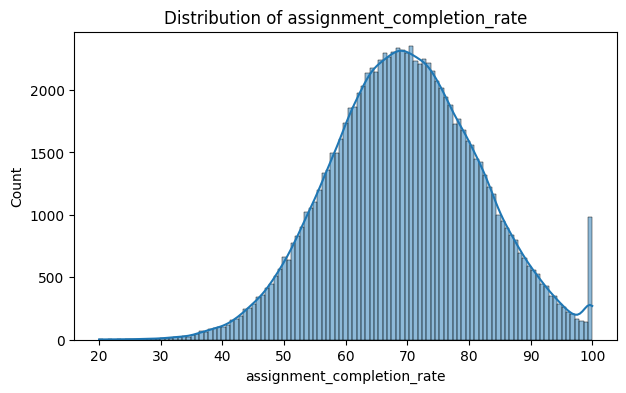

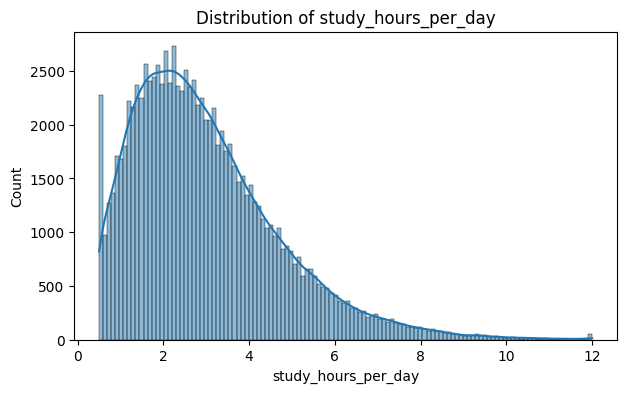

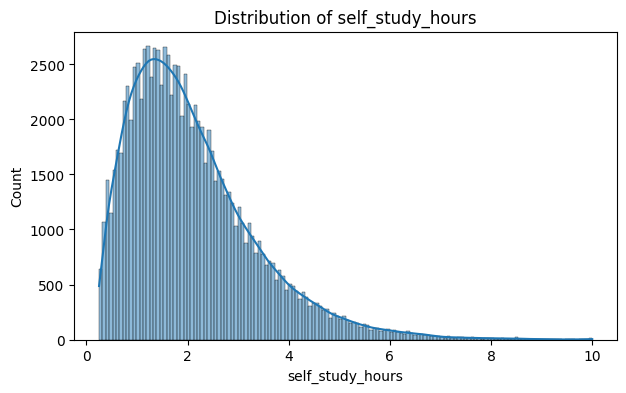

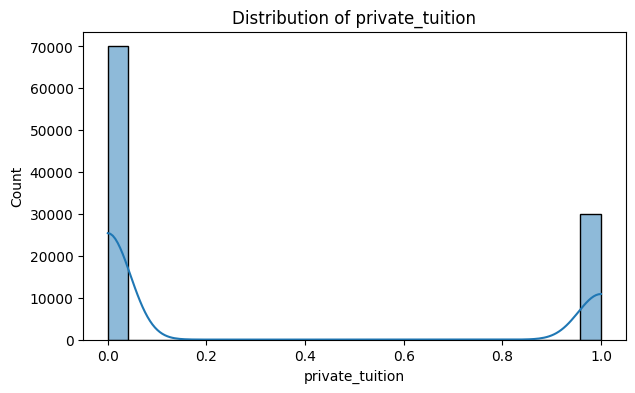

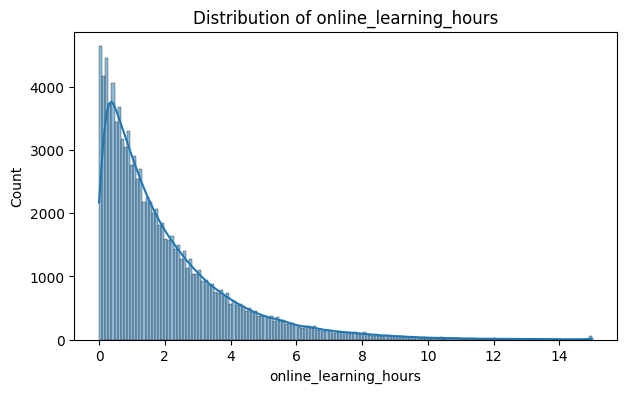

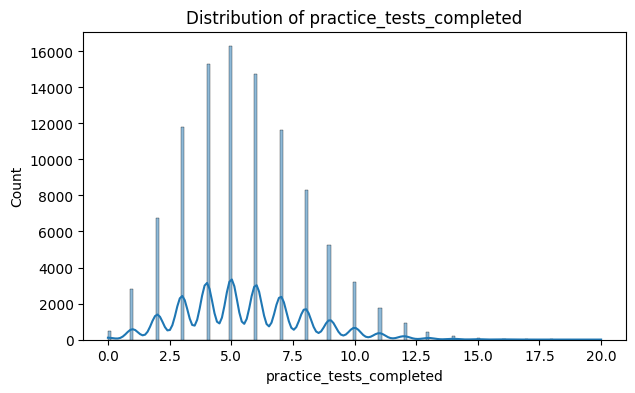

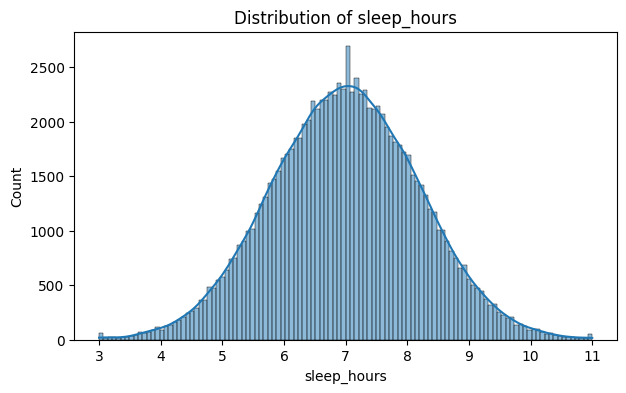

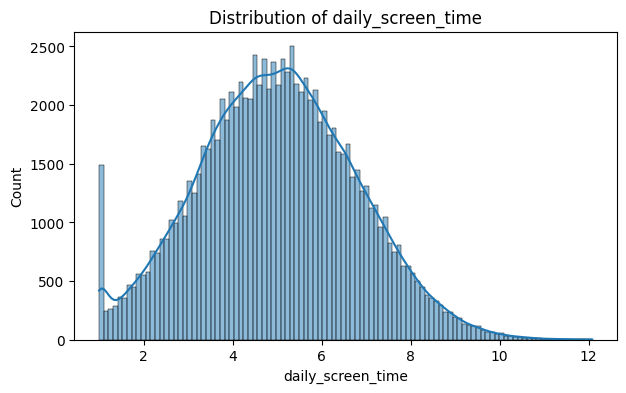

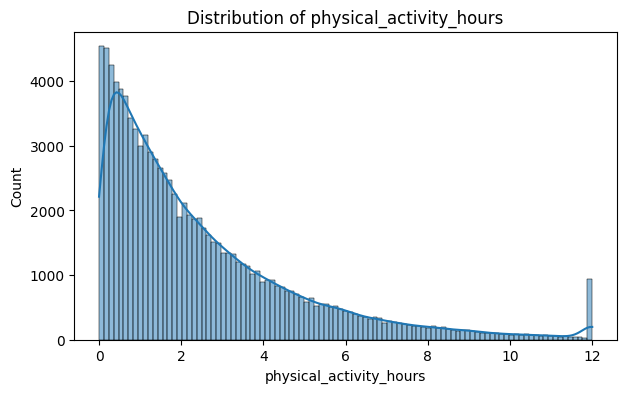

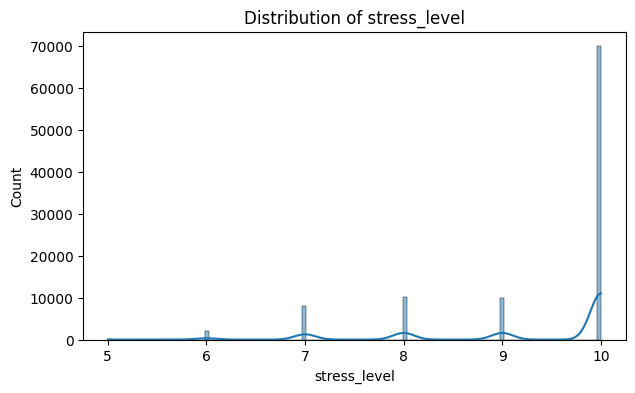

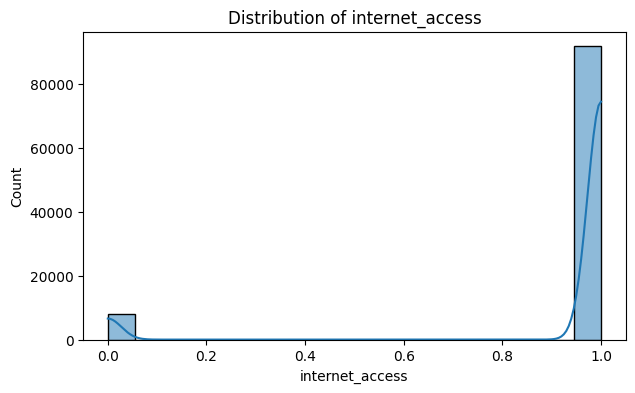

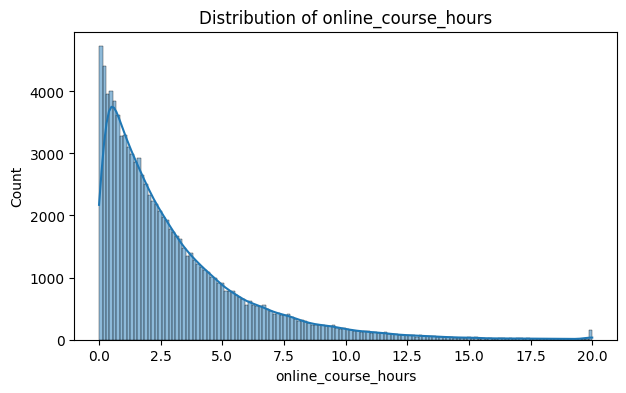

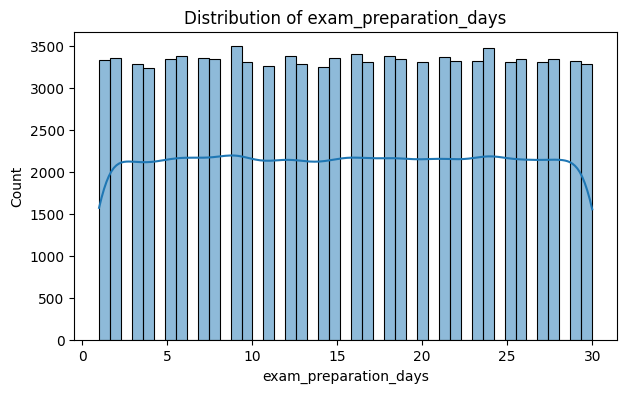

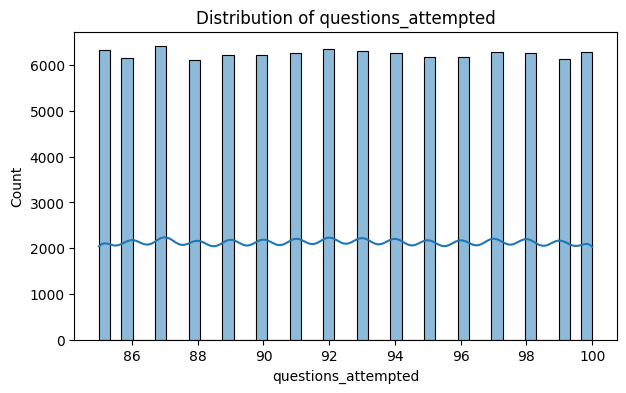

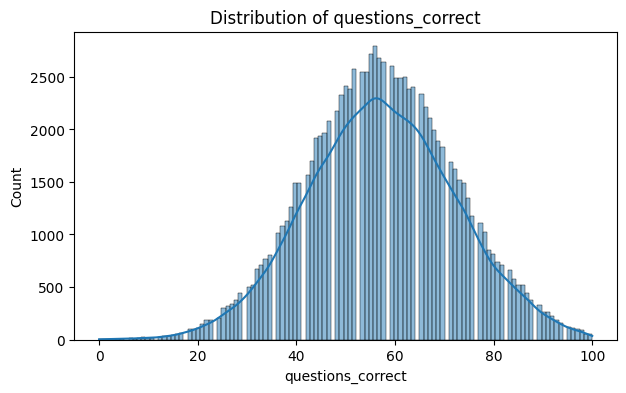

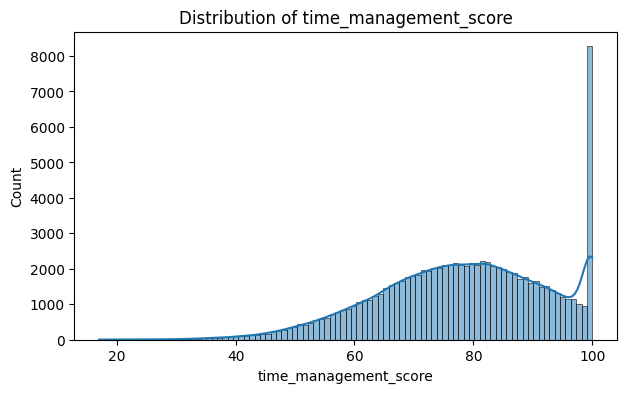

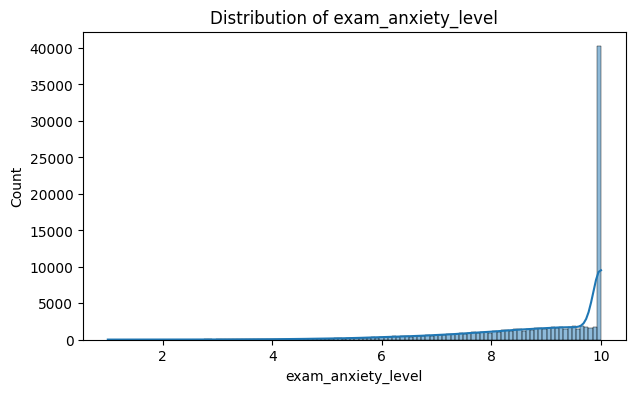

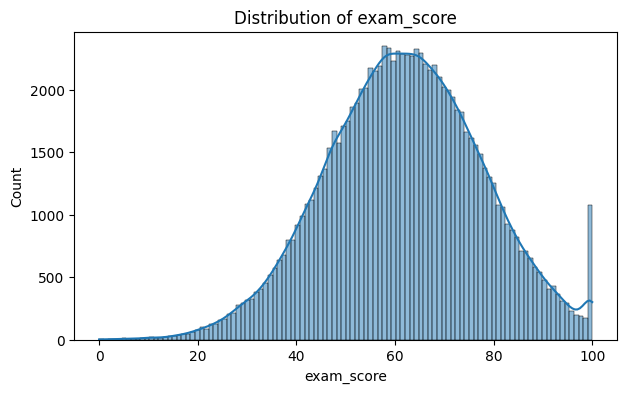

In [ ]:
numeric_features = df.select_dtypes(
    include=["int64", "float64"]
).columns

for feature in numeric_features:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=df, x=feature, kde=True)
    plt.title(f"Distribution of {feature}")
    plt.show()

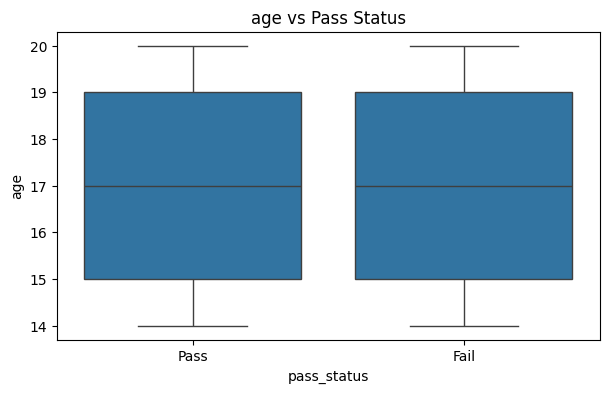

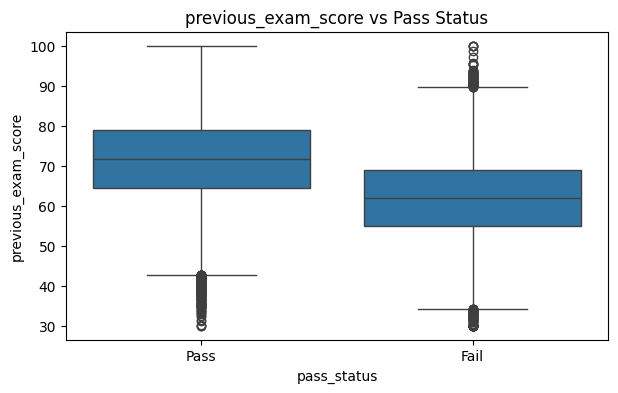

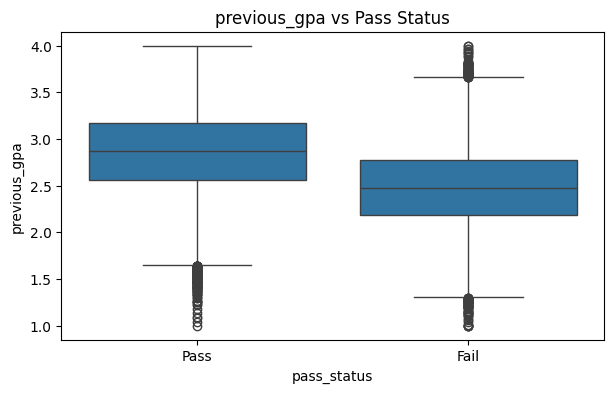

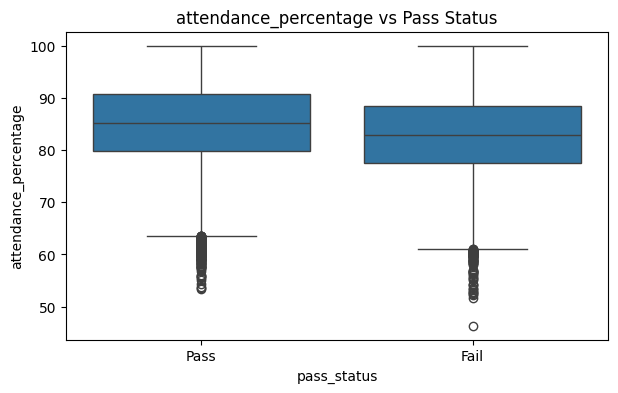

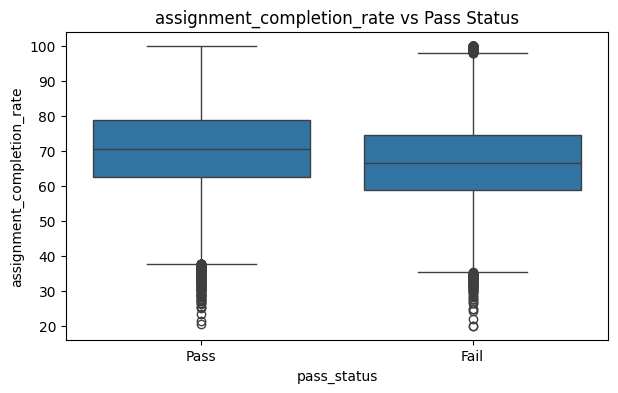

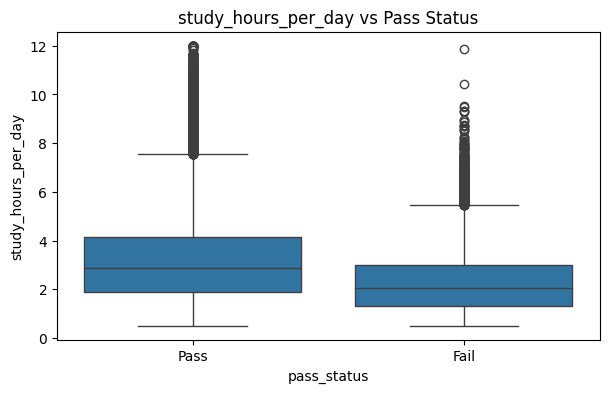

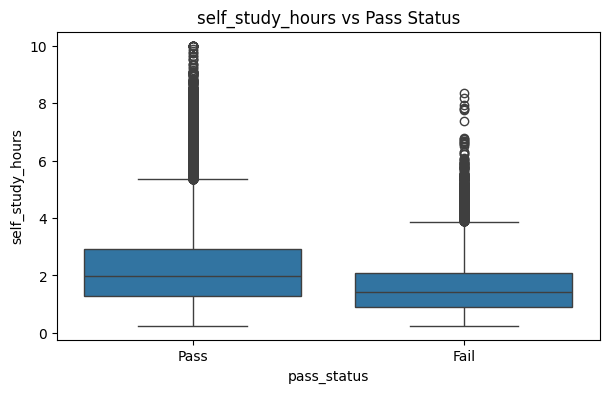

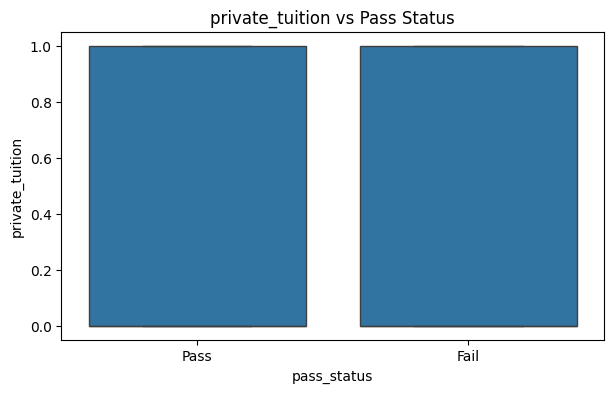

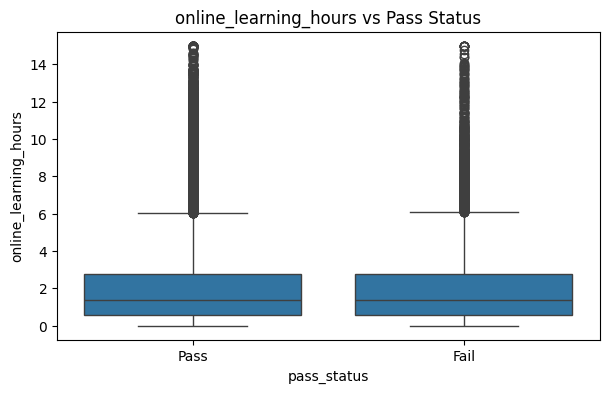

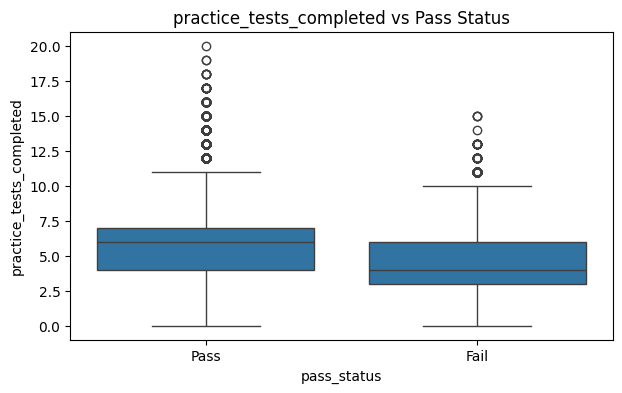

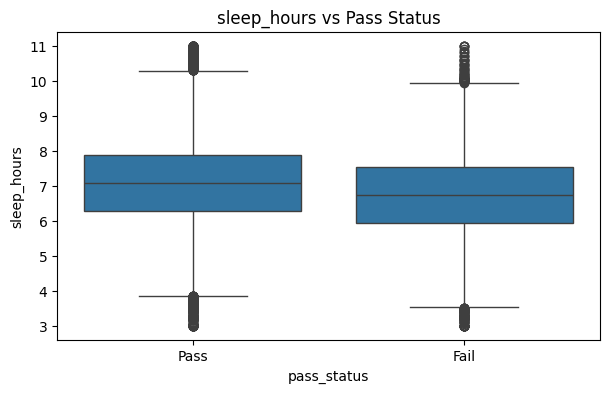

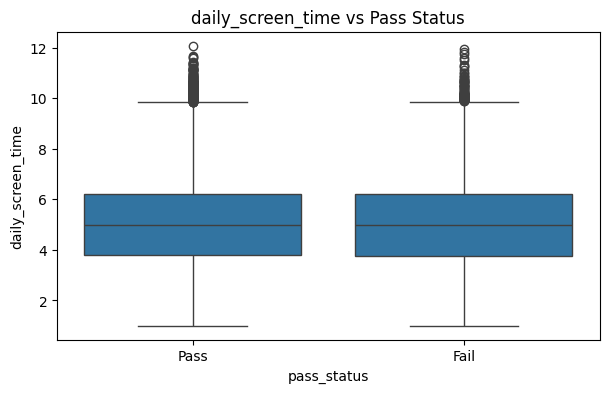

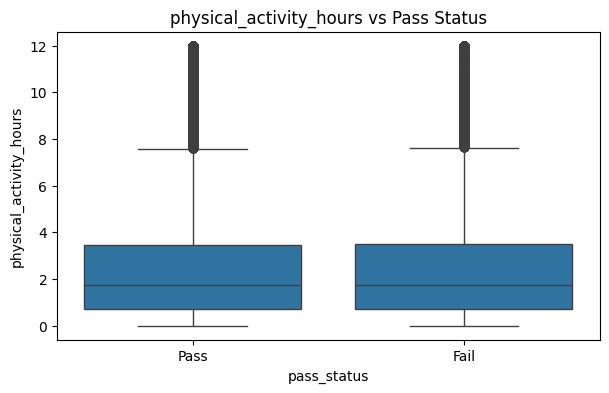

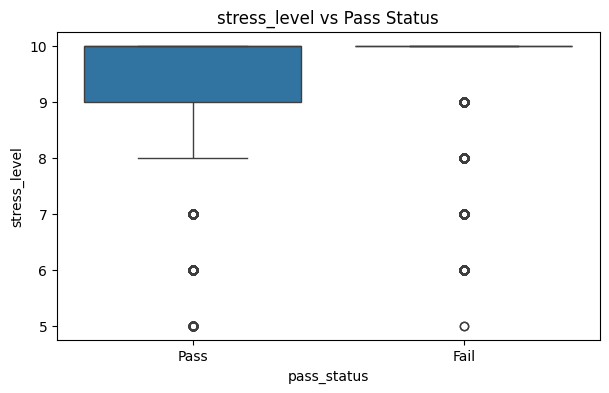

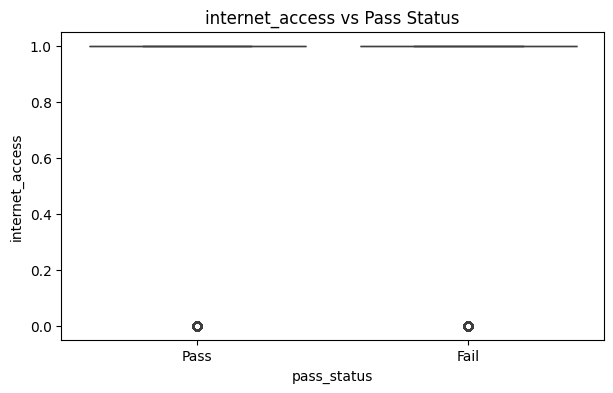

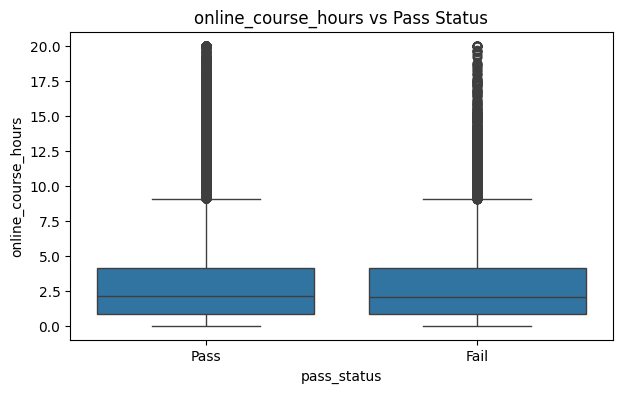

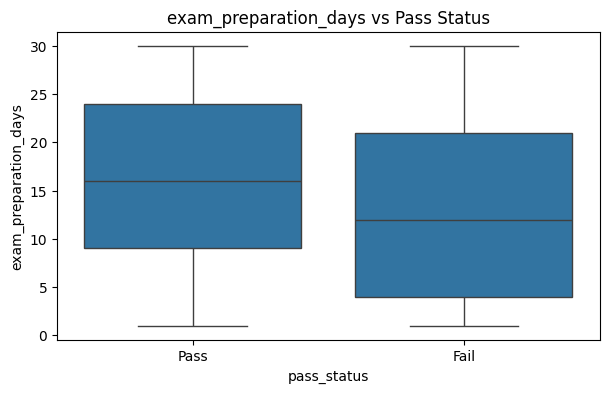

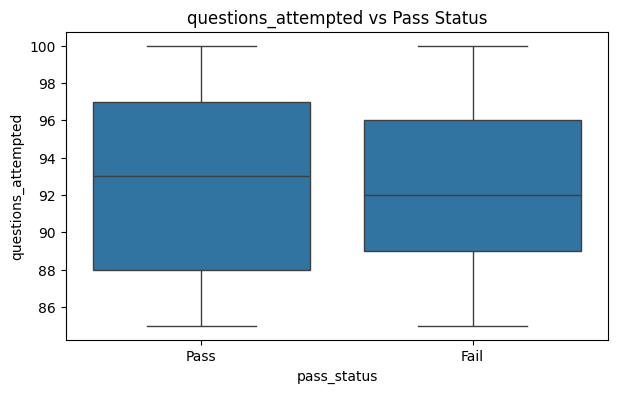

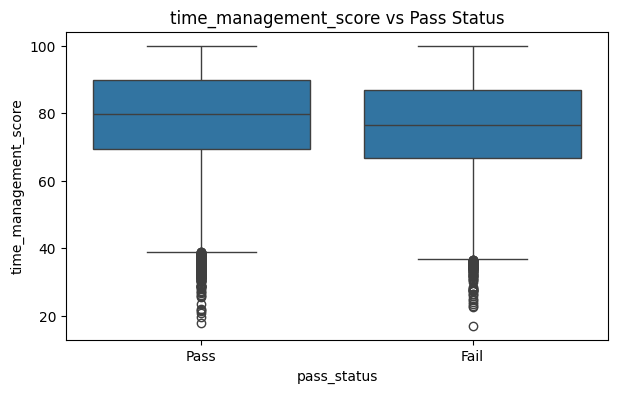

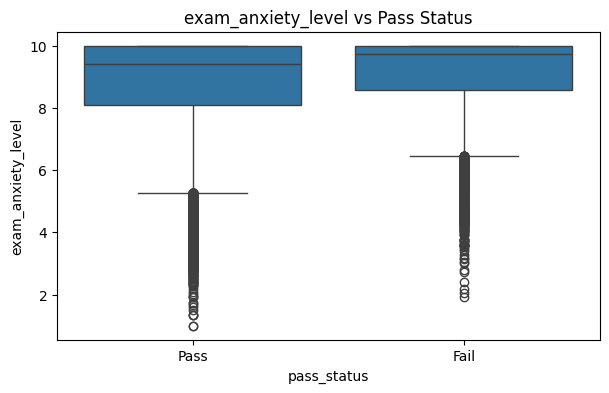

In [ ]:
for feature in numeric_features:

    if feature in ["exam_score", "questions_correct"]:
        continue

    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=df,
        x="pass_status",
        y=feature
    )

    plt.title(f"{feature} vs Pass Status")
    plt.show()

In [ ]:
missing = df.isnull().sum()

missing_percentage = (
    missing[missing > 0] / len(df)
) * 100

missing_percentage.sort_values(ascending=False)

,0
attendance_percentage,9.863
time_management_score,9.613
notes_quality,8.407
previous_gpa,7.793
sleep_quality,6.994
parent_education,6.526
device_availability,2.965


In [ ]:
y = df["pass_status"]

X = df.drop(columns=[
    "student_id",
    "pass_status",
    "exam_score",
    "questions_correct",
    "performance_grade",
    "performance_level"
])

In [ ]:
leakage_cols = [
    'exam_score',
    'questions_correct',
    'questions_attempted',
    'performance_grade',
    'performance_level',
    'student_id',
    'pass_status'
]

X = df.drop(columns=leakage_cols)
y = df["pass_status"]

In [ ]:

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

In [ ]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns

print("Numerical:")
print(numeric_features)

print("\nCategorical:")
print(categorical_features)

Numerical:
Index(['age', 'previous_exam_score', 'previous_gpa', 'attendance_percentage',
       'assignment_completion_rate', 'study_hours_per_day', 'self_study_hours',
       'private_tuition', 'online_learning_hours', 'practice_tests_completed',
       'sleep_hours', 'daily_screen_time', 'physical_activity_hours',
       'stress_level', 'internet_access', 'online_course_hours',
       'exam_preparation_days', 'time_management_score', 'exam_anxiety_level'],
      dtype='object')

Categorical:
Index(['gender', 'education_level', 'school_type', 'family_income',
       'parent_education', 'urban_rural', 'class_participation',
       'study_consistency', 'study_environment', 'study_method',
       'revision_frequency', 'notes_quality', 'sleep_quality',
       'break_frequency', 'motivation_level', 'device_availability',
       'educational_app_usage', 'exam_difficulty'],
      dtype='object')


In [ ]:
for feature in numeric_features:
    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[feature] < lower) |
        (df[feature] > upper)
    ][feature]

    print(f"{feature}: {len(outliers)} outliers")

age: 0 outliers
previous_exam_score: 327 outliers
previous_gpa: 296 outliers
attendance_percentage: 338 outliers
assignment_completion_rate: 303 outliers
study_hours_per_day: 2587 outliers
self_study_hours: 2971 outliers
private_tuition: 0 outliers
online_learning_hours: 4959 outliers
practice_tests_completed: 1724 outliers
sleep_hours: 672 outliers
daily_screen_time: 307 outliers
physical_activity_hours: 4855 outliers
stress_level: 10038 outliers
internet_access: 8124 outliers
online_course_hours: 4885 outliers
exam_preparation_days: 0 outliers
time_management_score: 340 outliers
exam_anxiety_level: 2901 outliers


In [ ]:
for feature in [
    "study_hours_per_day",
    "self_study_hours",
    "online_learning_hours",
    "physical_activity_hours",
    "stress_level",
    "internet_access",
    "online_course_hours",
    "exam_anxiety_level"
]:
    print(f"\n{feature}")
    print("Min:", df[feature].min())
    print("Max:", df[feature].max())
    print("Unique:", df[feature].nunique())


study_hours_per_day
Min: 0.5
Max: 12.0
Unique: 1073

self_study_hours
Min: 0.25
Max: 10.0
Unique: 856

online_learning_hours
Min: 0.0
Max: 15.0
Unique: 1330

physical_activity_hours
Min: 0.0
Max: 12.0
Unique: 1197

stress_level
Min: 5
Max: 10
Unique: 6

internet_access
Min: 0
Max: 1
Unique: 2

online_course_hours
Min: 0.0
Max: 20.0
Unique: 1804

exam_anxiety_level
Min: 1.0
Max: 10.0
Unique: 759


In [ ]:
print(df["stress_level"].value_counts().sort_index())
print()
print(df["internet_access"].value_counts().sort_index())

stress_level
5        76
6      2016
7      7946
8     10073
9     10008
10    69881
Name: count, dtype: int64

internet_access
0     8124
1    91876
Name: count, dtype: int64


In [ ]:


num_imputer = SimpleImputer(strategy="median")

X_train_num = pd.DataFrame(
    num_imputer.fit_transform(X_train[numeric_features]),
    columns=numeric_features,
    index=X_train.index
)

X_val_num = pd.DataFrame(
    num_imputer.transform(X_val[numeric_features]),
    columns=numeric_features,
    index=X_val.index
)

X_test_num = pd.DataFrame(
    num_imputer.transform(X_test[numeric_features]),
    columns=numeric_features,
    index=X_test.index
)

In [ ]:
cat_imputer = SimpleImputer(strategy="most_frequent")

X_train_cat = pd.DataFrame(
    cat_imputer.fit_transform(X_train[categorical_features]),
    columns=categorical_features,
    index=X_train.index
)

X_val_cat = pd.DataFrame(
    cat_imputer.transform(X_val[categorical_features]),
    columns=categorical_features,
    index=X_val.index
)

X_test_cat = pd.DataFrame(
    cat_imputer.transform(X_test[categorical_features]),
    columns=categorical_features,
    index=X_test.index
)

In [ ]:
print("Train numerical missing:")
print(X_train_num.isnull().sum().sum())

print("\nTrain categorical missing:")
print(X_train_cat.isnull().sum().sum())

print("\nValidation numerical missing:")
print(X_val_num.isnull().sum().sum())

print("\nValidation categorical missing:")
print(X_val_cat.isnull().sum().sum())

print("\nTest numerical missing:")
print(X_test_num.isnull().sum().sum())

print("\nTest categorical missing:")
print(X_test_cat.isnull().sum().sum())

Train numerical missing:
0

Train categorical missing:
0

Validation numerical missing:
0

Validation categorical missing:
0

Test numerical missing:
0

Test categorical missing:
0


In [ ]:
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)
X_train_cat_encoded = encoder.fit_transform(X_train_cat)

X_val_cat_encoded = encoder.transform(X_val_cat)

X_test_cat_encoded = encoder.transform(X_test_cat)

In [ ]:
print("Train encoded shape:", X_train_cat_encoded.shape)
print("Validation encoded shape:", X_val_cat_encoded.shape)
print("Test encoded shape:", X_test_cat_encoded.shape)

Train encoded shape: (80000, 59)
Validation encoded shape: (10000, 59)
Test encoded shape: (10000, 59)


In [ ]:

scaler = StandardScaler()

X_train_num_scaled = scaler.fit_transform(X_train_num)

X_val_num_scaled = scaler.transform(X_val_num)

X_test_num_scaled = scaler.transform(X_test_num)

In [ ]:
import numpy as np

X_train_processed = np.hstack([
    X_train_num_scaled,
    X_train_cat_encoded
])

X_val_processed = np.hstack([
    X_val_num_scaled,
    X_val_cat_encoded
])

X_test_processed = np.hstack([
    X_test_num_scaled,
    X_test_cat_encoded
])

In [ ]:
print("X_train:", X_train_processed.shape)
print("X_val:", X_val_processed.shape)
print("X_test:", X_test_processed.shape)

X_train: (80000, 78)
X_val: (10000, 78)
X_test: (10000, 78)


In [ ]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

logistic_model.fit(X_train_processed, y_train)

y_val_pred = logistic_model.predict(X_val_processed)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Accuracy :", accuracy_score(y_val, y_val_pred))
print("Precision:", precision_score(y_val, y_val_pred, pos_label="Pass"))
print("Recall   :", recall_score(y_val, y_val_pred, pos_label="Pass"))
print("F1 Score :", f1_score(y_val, y_val_pred, pos_label="Pass"))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))

Accuracy : 0.8483
Precision: 0.8759062348960851
Recall   : 0.9366843261403283
F1 Score : 0.9052763034655011

Classification Report:
              precision    recall  f1-score   support

        Fail       0.72      0.55      0.62      2261
        Pass       0.88      0.94      0.91      7739

    accuracy                           0.85     10000
   macro avg       0.80      0.74      0.76     10000
weighted avg       0.84      0.85      0.84     10000


Confusion Matrix:
[[1234 1027]
 [ 490 7249]]


In [ ]:
import numpy as np
from sklearn.metrics import precision_recall_curve

def find_best_threshold(model, x_val, y_val):

    pos_idx = list(model.classes_).index("Fail")
    y_scores = model.predict_proba(x_val)[:, pos_idx]

    precision, recall, thresholds = precision_recall_curve(
        y_val == "Fail",
        y_scores
    )

    f1_scores = (
        2 * precision[:-1] * recall[:-1]
    ) / (
        precision[:-1] + recall[:-1] + 1e-10
    )

    best_index = np.argmax(f1_scores)

    best_threshold = thresholds[best_index]
    best_f1 = f1_scores[best_index]

    return best_threshold, best_f1


In [ ]:
best_threshold, best_f1 = find_best_threshold(
    logistic_model,
    X_val_processed,
    y_val
)

print("Best Threshold:", best_threshold)
print("Best Fail F1:", best_f1)

Best Threshold: 0.30178959197494126
Best Fail F1: 0.6667964187907343


In [ ]:
pos_idx = list(logistic_model.classes_).index("Fail")
y_scores = logistic_model.predict_proba(X_val_processed)[:, pos_idx]

y_val_pred_optimized = np.where(
    y_scores >= best_threshold,
    "Fail",
    "Pass"
)


In [ ]:
print("Accuracy:",
      accuracy_score(y_val, y_val_pred_optimized))

print("Fail Precision:",
      precision_score(
          y_val,
          y_val_pred_optimized,
          pos_label="Fail"
      ))

print("Fail Recall:",
      recall_score(
          y_val,
          y_val_pred_optimized,
          pos_label="Fail"
      ))

print("Fail F1:",
      f1_score(
          y_val,
          y_val_pred_optimized,
          pos_label="Fail"
      ))

print(classification_report(
    y_val,
    y_val_pred_optimized
))

print(confusion_matrix(
    y_val,
    y_val_pred_optimized
))

Accuracy: 0.8288
Fail Precision: 0.5954118873826904
Fail Recall: 0.7576293675364882
Fail F1: 0.6667964188400156
              precision    recall  f1-score   support

        Fail       0.60      0.76      0.67      2261
        Pass       0.92      0.85      0.88      7739

    accuracy                           0.83     10000
   macro avg       0.76      0.80      0.78     10000
weighted avg       0.85      0.83      0.84     10000

[[1713  548]
 [1164 6575]]


In [ ]:
knn_model = KNeighborsClassifier(
    n_neighbors=5
)
knn_model.fit(
    X_train_processed,
    y_train
)


KNeighborsClassifier()

In [ ]:
y_val_pred_knn = knn_model.predict(
    X_val_processed
)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:",
      accuracy_score(y_val, y_val_pred_knn))

print("Fail Precision:",
      precision_score(
          y_val,
          y_val_pred_knn,
          pos_label="Fail"
      ))

print("Fail Recall:",
      recall_score(
          y_val,
          y_val_pred_knn,
          pos_label="Fail"
      ))

print("Fail F1:",
      f1_score(
          y_val,
          y_val_pred_knn,
          pos_label="Fail"
      ))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_knn))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_knn))

Accuracy: 0.7946
Fail Precision: 0.5760470242468773
Fail Recall: 0.34674922600619196
Fail F1: 0.43290999447818884

Classification Report:
              precision    recall  f1-score   support

        Fail       0.58      0.35      0.43      2261
        Pass       0.83      0.93      0.87      7739

    accuracy                           0.79     10000
   macro avg       0.70      0.64      0.65     10000
weighted avg       0.77      0.79      0.77     10000


Confusion Matrix:
[[ 784 1477]
 [ 577 7162]]


In [ ]:
X_train_svm, _, y_train_svm, _ = train_test_split(
    X_train_processed,
    y_train,
    train_size=20000,
    random_state=42,
    stratify=y_train
)

In [ ]:
from sklearn.svm import SVC

svm_model = SVC(
    random_state=42
)

svm_model.fit(
    X_train_svm,
    y_train_svm
)

y_val_pred_svm = svm_model.predict(X_val_processed)

In [ ]:
print("Accuracy:",
      accuracy_score(y_val, y_val_pred_svm))

print("Fail Precision:",
      precision_score(y_val, y_val_pred_svm, pos_label="Fail"))

print("Fail Recall:",
      recall_score(y_val, y_val_pred_svm, pos_label="Fail"))

print("Fail F1:",
      f1_score(y_val, y_val_pred_svm, pos_label="Fail"))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_svm))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_svm))

Accuracy: 0.8493
Fail Precision: 0.7371069182389937
Fail Recall: 0.5183547103051747
Fail F1: 0.608673071929369

Classification Report:
              precision    recall  f1-score   support

        Fail       0.74      0.52      0.61      2261
        Pass       0.87      0.95      0.91      7739

    accuracy                           0.85     10000
   macro avg       0.80      0.73      0.76     10000
weighted avg       0.84      0.85      0.84     10000


Confusion Matrix:
[[1172 1089]
 [ 418 7321]]


In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(
    X_train_processed,
    y_train
)

y_val_pred_dt = dt_model.predict(
    X_val_processed
)

In [ ]:
print("Accuracy:",
      accuracy_score(y_val, y_val_pred_dt))

print("Fail Precision:",
      precision_score(y_val, y_val_pred_dt, pos_label="Fail"))

print("Fail Recall:",
      recall_score(y_val, y_val_pred_dt, pos_label="Fail"))

print("Fail F1:",
      f1_score(y_val, y_val_pred_dt, pos_label="Fail"))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_dt))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_dt))

Accuracy: 0.783
Fail Precision: 0.5197225834416992
Fail Recall: 0.530296329057939
Fail F1: 0.5249562171628721

Classification Report:
              precision    recall  f1-score   support

        Fail       0.52      0.53      0.52      2261
        Pass       0.86      0.86      0.86      7739

    accuracy                           0.78     10000
   macro avg       0.69      0.69      0.69     10000
weighted avg       0.78      0.78      0.78     10000


Confusion Matrix:
[[1199 1062]
 [1108 6631]]


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train_processed,
    y_train
)

y_val_pred_rf = rf_model.predict(
    X_val_processed
)

In [ ]:
print("Accuracy:",
      accuracy_score(y_val, y_val_pred_rf))

print("Fail Precision:",
      precision_score(y_val, y_val_pred_rf, pos_label="Fail"))

print("Fail Recall:",
      recall_score(y_val, y_val_pred_rf, pos_label="Fail"))

print("Fail F1:",
      f1_score(y_val, y_val_pred_rf, pos_label="Fail"))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_rf))

Accuracy: 0.847
Fail Precision: 0.7642805495300072
Fail Recall: 0.4674922600619195
Fail F1: 0.5801317233809001

Classification Report:
              precision    recall  f1-score   support

        Fail       0.76      0.47      0.58      2261
        Pass       0.86      0.96      0.91      7739

    accuracy                           0.85     10000
   macro avg       0.81      0.71      0.74     10000
weighted avg       0.84      0.85      0.83     10000


Confusion Matrix:
[[1057 1204]
 [ 326 7413]]


In [ ]:
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()

nb_model.fit(
    X_train_processed,
    y_train
)

y_val_pred_nb = nb_model.predict(
    X_val_processed
)

In [ ]:
print("Accuracy:",
      accuracy_score(y_val, y_val_pred_nb))

print("Fail Precision:",
      precision_score(y_val, y_val_pred_nb, pos_label="Fail"))

print("Fail Recall:",
      recall_score(y_val, y_val_pred_nb, pos_label="Fail"))

print("Fail F1:",
      f1_score(y_val, y_val_pred_nb, pos_label="Fail"))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_nb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_nb))

Accuracy: 0.8067
Fail Precision: 0.56047197640118
Fail Recall: 0.6722689075630253
Fail F1: 0.6113010255379047

Classification Report:
              precision    recall  f1-score   support

        Fail       0.56      0.67      0.61      2261
        Pass       0.90      0.85      0.87      7739

    accuracy                           0.81     10000
   macro avg       0.73      0.76      0.74     10000
weighted avg       0.82      0.81      0.81     10000


Confusion Matrix:
[[1520  741]
 [1192 6547]]


In [ ]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=100,
    random_state=42,
    eval_metric="logloss"
)



In [ ]:
y_train_xgb = (y_train == "Fail").astype(int)
y_val_xgb = (y_val == "Fail").astype(int)

In [ ]:
xgb_model.fit(
    X_train_processed,
    y_train_xgb
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

In [ ]:
y_val_pred_xgb = xgb_model.predict(
    X_val_processed
)

In [ ]:
print("Accuracy:",
      accuracy_score(y_val_xgb, y_val_pred_xgb))

print("Fail Precision:",
      precision_score(y_val_xgb, y_val_pred_xgb))

print("Fail Recall:",
      recall_score(y_val_xgb, y_val_pred_xgb))

print("Fail F1:",
      f1_score(y_val_xgb, y_val_pred_xgb))

print("\nClassification Report:")
print(classification_report(
    y_val_xgb,
    y_val_pred_xgb,
    target_names=["Pass", "Fail"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_val_xgb,
    y_val_pred_xgb
))

Accuracy: 0.8531
Fail Precision: 0.7133620689655172
Fail Recall: 0.5855816010614773
Fail F1: 0.6431867864950207

Classification Report:
              precision    recall  f1-score   support

        Pass       0.88      0.93      0.91      7739
        Fail       0.71      0.59      0.64      2261

    accuracy                           0.85     10000
   macro avg       0.80      0.76      0.78     10000
weighted avg       0.85      0.85      0.85     10000


Confusion Matrix:
[[7207  532]
 [ 937 1324]]


In [ ]:
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier

xgb = XGBClassifier(
    random_state=42,
    eval_metric="logloss"
)

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.05, 0.1],
    "subsample": [0.8, 1.0]
}

grid_search = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(
    X_train_processed,
    y_train_xgb
)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest CV F1:")
print(grid_search.best_score_)

Fitting 3 folds for each of 36 candidates, totalling 108 fits
Best Parameters:
{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 300, 'subsample': 0.8}

Best CV F1:
0.6427564366419225


In [ ]:
best_xgb = grid_search.best_estimator_
y_val_pred_xgb_tuned = best_xgb.predict(X_val_processed)

print("Accuracy:",
      accuracy_score(y_val_xgb, y_val_pred_xgb_tuned))

print("Fail Precision:",
      precision_score(y_val_xgb, y_val_pred_xgb_tuned))

print("Fail Recall:",
      recall_score(y_val_xgb, y_val_pred_xgb_tuned))

print("Fail F1:",
      f1_score(y_val_xgb, y_val_pred_xgb_tuned))

print("\nClassification Report:")
print(classification_report(
    y_val_xgb,
    y_val_pred_xgb_tuned,
    target_names=["Pass", "Fail"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_xgb, y_val_pred_xgb_tuned))

Accuracy: 0.8586
Fail Precision: 0.7356705620478575
Fail Recall: 0.5846970367094206
Fail F1: 0.6515524889107935

Classification Report:
              precision    recall  f1-score   support

        Pass       0.89      0.94      0.91      7739
        Fail       0.74      0.58      0.65      2261

    accuracy                           0.86     10000
   macro avg       0.81      0.76      0.78     10000
weighted avg       0.85      0.86      0.85     10000


Confusion Matrix:
[[7264  475]
 [ 939 1322]]


In [ ]:
y_val_scores_xgb = best_xgb.predict_proba(X_val_processed)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_val_xgb,
    y_val_scores_xgb
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
) / (
    precision[:-1] + recall[:-1] + 1e-10
)

best_index = np.argmax(f1_scores)

best_threshold_xgb = thresholds[best_index]
best_f1_xgb = f1_scores[best_index]

print("Best Threshold:", best_threshold_xgb)
print("Best Fail F1:", best_f1_xgb)

Best Threshold: 0.3173027
Best Fail F1: 0.6798166965035886


In [ ]:
y_val_pred_xgb_optimized = (
    y_val_scores_xgb >= best_threshold_xgb
).astype(int)
print("Accuracy:",
      accuracy_score(y_val_xgb, y_val_pred_xgb_optimized))

print("Fail Precision:",
      precision_score(y_val_xgb, y_val_pred_xgb_optimized))

print("Fail Recall:",
      recall_score(y_val_xgb, y_val_pred_xgb_optimized))

print("Fail F1:",
      f1_score(y_val_xgb, y_val_pred_xgb_optimized))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_xgb, y_val_pred_xgb_optimized))

Accuracy: 0.8393
Fail Precision: 0.6185641769398115
Fail Recall: 0.7545333923042902
Fail F1: 0.6798166965530982

Confusion Matrix:
[[6687 1052]
 [ 555 1706]]


In [ ]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_processed,
    y_train_xgb
)

print("Before SMOTE:")
print(y_train_xgb.value_counts())

print("\nAfter SMOTE:")
print(pd.Series(y_train_smote).value_counts())

Before SMOTE:
pass_status
0    61911
1    18089
Name: count, dtype: int64

After SMOTE:
pass_status
0    61911
1    61911
Name: count, dtype: int64


In [ ]:
xgb_smote = XGBClassifier(
    learning_rate=0.1,
    max_depth=3,
    n_estimators=300,
    subsample=0.8,
    random_state=42,
    eval_metric="logloss"
)

xgb_smote.fit(
    X_train_smote,
    y_train_smote
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=None,
              num_parallel_tree=None, ...)

In [ ]:
y_val_pred_xgb_smote = xgb_smote.predict(
    X_val_processed
)


print("Accuracy:",
      accuracy_score(y_val_xgb, y_val_pred_xgb_smote))

print("Fail Precision:",
      precision_score(y_val_xgb, y_val_pred_xgb_smote))

print("Fail Recall:",
      recall_score(y_val_xgb, y_val_pred_xgb_smote))

print("Fail F1:",
      f1_score(y_val_xgb, y_val_pred_xgb_smote))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_xgb, y_val_pred_xgb_smote))

Accuracy: 0.8577
Fail Precision: 0.7238247863247863
Fail Recall: 0.5992923485183547
Fail F1: 0.6556980401645294

Confusion Matrix:
[[7222  517]
 [ 906 1355]]


In [ ]:


y_val_scores_smote = xgb_smote.predict_proba(
    X_val_processed
)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_val_xgb,
    y_val_scores_smote
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
) / (
    precision[:-1] + recall[:-1] + 1e-10
)

best_index = np.argmax(f1_scores)

best_threshold_smote = thresholds[best_index]
best_f1_smote = f1_scores[best_index]

print("Best Threshold:", best_threshold_smote)
print("Best Fail F1:", best_f1_smote)

Best Threshold: 0.3820324
Best Fail F1: 0.6800838573924832


In [ ]:
y_val_pred_smote_optimized = (
    y_val_scores_smote >= best_threshold_smote
).astype(int)

print("Accuracy:",
      accuracy_score(y_val_xgb, y_val_pred_smote_optimized))

print("Fail Precision:",
      precision_score(y_val_xgb, y_val_pred_smote_optimized))

print("Fail Recall:",
      recall_score(y_val_xgb, y_val_pred_smote_optimized))

print("Fail F1:",
      f1_score(y_val_xgb, y_val_pred_smote_optimized))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_val_xgb,
    y_val_pred_smote_optimized
))

Accuracy: 0.8474
Fail Precision: 0.6464726982861698
Fail Recall: 0.7173816895179125
Fail F1: 0.680083857442348

Confusion Matrix:
[[6852  887]
 [ 639 1622]]


In [ ]:
from sklearn.metrics import accuracy_score, classification_report

def get_results(y_true, y_pred, binary_numeric=False):

    if binary_numeric:
        report = classification_report(
            y_true,
            y_pred,
            output_dict=True,
            zero_division=0
        )

        return {
            "Accuracy": accuracy_score(y_true, y_pred),

            "Pass Precision": report["0"]["precision"],
            "Pass Recall": report["0"]["recall"],
            "Pass F1": report["0"]["f1-score"],

            "Fail Precision": report["1"]["precision"],
            "Fail Recall": report["1"]["recall"],
            "Fail F1": report["1"]["f1-score"]
        }

    else:
        report = classification_report(
            y_true,
            y_pred,
            output_dict=True,
            zero_division=0
        )

        return {
            "Accuracy": accuracy_score(y_true, y_pred),

            "Pass Precision": report["Pass"]["precision"],
            "Pass Recall": report["Pass"]["recall"],
            "Pass F1": report["Pass"]["f1-score"],

            "Fail Precision": report["Fail"]["precision"],
            "Fail Recall": report["Fail"]["recall"],
            "Fail F1": report["Fail"]["f1-score"]
        }


In [ ]:
results = {}
results["Logistic Regression"] = get_results(
    y_val,
    y_val_pred
)

In [ ]:
results["XGBoost"] = get_results(
    y_val_xgb,
    y_val_pred_xgb,
    binary_numeric=True
)

results["XGBoost Tuned"] = get_results(
    y_val_xgb,
    y_val_pred_xgb_tuned,
    binary_numeric=True
)

results["XGBoost Tuned + Threshold"] = get_results(
    y_val_xgb,
    y_val_pred_xgb_optimized,
    binary_numeric=True
)

In [ ]:
results_df = pd.DataFrame(results).T

print(results_df.round(4))

                           Accuracy  Pass Precision  Pass Recall  Pass F1  \
Logistic Regression          0.8483          0.8759       0.9367   0.9053   
XGBoost                      0.8531          0.8849       0.9313   0.9075   
XGBoost Tuned                0.8586          0.8855       0.9386   0.9113   
XGBoost Tuned + Threshold    0.8393          0.9234       0.8641   0.8927   

                           Fail Precision  Fail Recall  Fail F1  
Logistic Regression                0.7158       0.5458   0.6193  
XGBoost                            0.7134       0.5856   0.6432  
XGBoost Tuned                      0.7357       0.5847   0.6516  
XGBoost Tuned + Threshold          0.6186       0.7545   0.6798  


In [ ]:
import joblib

model_package = {
    "model": best_xgb,
    "threshold": best_threshold_xgb,
    "num_imputer": num_imputer,
    "cat_imputer": cat_imputer,
    "encoder": encoder,
    "scaler": scaler,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features
}

joblib.dump(model_package, "student_pass_xgboost.pkl")

['student_pass_xgboost.pkl']

In [ ]:
y_test_xgb = (y_test == "Fail").astype(int)


In [ ]:
y_test_scores = best_xgb.predict_proba(X_test_processed)[:, 1]

y_test_pred_xgb = (y_test_scores >= best_threshold_xgb).astype(int)

print("Accuracy:",
      accuracy_score(y_test_xgb, y_test_pred_xgb))

print("Fail Precision:",
      precision_score(y_test_xgb, y_test_pred_xgb))

print("Fail Recall:",
      recall_score(y_test_xgb, y_test_pred_xgb))

print("Fail F1:",
      f1_score(y_test_xgb, y_test_pred_xgb))

print("\nClassification Report:")
print(classification_report(
    y_test_xgb,
    y_test_pred_xgb,
    target_names=["Pass", "Fail"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_xgb, y_test_pred_xgb))


In [ ]:
y_test_scores_smote = xgb_smote.predict_proba(X_test_processed)[:, 1]

y_test_pred_smote = (y_test_scores_smote >= best_threshold_smote).astype(int)

print("Accuracy:",
      accuracy_score(y_test_xgb, y_test_pred_smote))

print("Fail Precision:",
      precision_score(y_test_xgb, y_test_pred_smote))

print("Fail Recall:",
      recall_score(y_test_xgb, y_test_pred_smote))

print("Fail F1:",
      f1_score(y_test_xgb, y_test_pred_smote))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_xgb, y_test_pred_smote))


In [ ]:
pos_idx = list(logistic_model.classes_).index("Fail")
y_test_scores_lr = logistic_model.predict_proba(X_test_processed)[:, pos_idx]

y_test_pred_lr = np.where(
    y_test_scores_lr >= best_threshold,
    "Fail",
    "Pass"
)

print("Accuracy:",
      accuracy_score(y_test, y_test_pred_lr))

print("Fail Precision:",
      precision_score(y_test, y_test_pred_lr, pos_label="Fail"))

print("Fail Recall:",
      recall_score(y_test, y_test_pred_lr, pos_label="Fail"))

print("Fail F1:",
      f1_score(y_test, y_test_pred_lr, pos_label="Fail"))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_lr))


In [ ]:
results["XGBoost Tuned + Threshold (Test)"] = get_results(
    y_test_xgb,
    y_test_pred_xgb,
    binary_numeric=True
)

results["XGBoost SMOTE + Threshold (Test)"] = get_results(
    y_test_xgb,
    y_test_pred_smote,
    binary_numeric=True
)

results["Logistic + Threshold (Test)"] = get_results(
    y_test,
    y_test_pred_lr
)

results_df = pd.DataFrame(results).T
print(results_df.round(4))


In [ ]:
import joblib

model_package = {
    "model": best_xgb,
    "threshold": best_threshold_xgb,
    "num_imputer": num_imputer,
    "cat_imputer": cat_imputer,
    "encoder": encoder,
    "scaler": scaler,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features
}

joblib.dump(model_package, "student_pass_xgboost.pkl")
